# Activity Recognition System: code walkthrough
**Project 24 · IBM Skill Lab · Review 2, 28 Nov 2026**

Each part is explained by the person who wrote that code. Every result below was produced by running this notebook top to bottom.

| Part | Explained by | Code |
|---|---|---|
| 1. The project and its settings | Yyug | `config/config.yaml` |
| 2. Loading and preprocessing | Nihal | `src/data_loader.py`, `src/preprocess.py` |
| 3. Checking a recording | Shravya | `src/validation.py` |
| 4. Models, training and evaluation | Yash | `src/models.py`, `src/train.py` |
| 5. Prediction and the app | Yashaswini | `src/inference.py`, `app/home.py` |
| 6. Activity from video | Yyug | `src/video_pose.py` |

**Jupyter on the laptop:** in the `activity-recognition` folder run `jupyter notebook notebooks/00_review_walkthrough.ipynb`.

**Google Colab:** [open this notebook in Colab](https://colab.research.google.com/github/rajyyug1132/activity-recognition/blob/main/notebooks/00_review_walkthrough.ipynb) and run the setup cell. It downloads the code, UCI HAR and the MediaPipe pose model, and copies `cnn_uci.keras` and `video_rf.joblib` from the top level of your Google Drive. Part 6 needs our own videos, which stay off GitHub for privacy, so in Colab it keeps the results saved here.

## Setup

In [1]:
import os, sys, subprocess, pathlib, urllib.request, zipfile, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not os.path.exists("/content/activity-recognition"):
        subprocess.run(["git", "clone", "-q", "https://github.com/rajyyug1132/activity-recognition", "/content/activity-recognition"], check=True)
    os.chdir("/content/activity-recognition")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mediapipe", "scikit-learn==1.9.1"], check=True)
    os.makedirs("data/uci", exist_ok=True); os.makedirs("models", exist_ok=True)
    if not os.path.exists("data/uci/UCI HAR Dataset"):
        urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip", "data/uci/har.zip")
        zipfile.ZipFile("data/uci/har.zip").extractall("data/uci")
        zipfile.ZipFile("data/uci/UCI HAR Dataset.zip").extractall("data/uci")
    if not os.path.exists("models/pose_landmarker_full.task"):
        urllib.request.urlretrieve("https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task", "models/pose_landmarker_full.task")
    from google.colab import drive
    drive.mount("/content/drive")
    for f in ["cnn_uci.keras", "video_rf.joblib"]:
        if os.path.exists(f"/content/drive/MyDrive/{f}"):
            subprocess.run(["cp", f"/content/drive/MyDrive/{f}", f"models/{f}"], check=True)
elif pathlib.Path.cwd().name == "notebooks":
    os.chdir("..")                      # run from the repository root

sys.path.insert(0, "src")
for f in ["config/config.yaml", "app/demo/uci_test_person_12.csv", "data/uci/UCI HAR Dataset",
          "models/cnn_uci.keras", "models/video_rf.joblib", "models/pose_landmarker_full.task"]:
    print("found  " if os.path.exists(f) else "MISSING", f)

found   config/config.yaml
found   app/demo/uci_test_person_12.csv
found   data/uci/UCI HAR Dataset
found   models/cnn_uci.keras
found   models/video_rf.joblib
found   models/pose_landmarker_full.task


In [2]:
%matplotlib inline
import inspect, yaml, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Code, Image, display
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def show(fn):
    """Print a function's source exactly as it is in src/."""
    display(Code(inspect.getsource(fn), language="python"))

cfg = yaml.safe_load(open("config/config.yaml"))
DEMO = "app/demo/uci_test_person_12.csv"
NAMES = {"WALKING": "Walking", "WALKING_UPSTAIRS": "Upstairs", "WALKING_DOWNSTAIRS": "Downstairs",
         "SITTING": "Sitting", "STANDING": "Standing", "LAYING": "Lying"}
COLOURS = {"WALKING": "#2bb3a3", "WALKING_DOWNSTAIRS": "#2b3a8f", "WALKING_UPSTAIRS": "#7fb8e6",
           "SITTING": "#e9853a", "STANDING": "#e8c547", "LAYING": "#7a2e6e"}

## 1. The project and its settings · Yyug
**What to say**
- From a phone worn at the waist, the model labels every 2.56-second window as walking, upstairs, downstairs, sitting, standing or lying.
- Every setting lives in one file, `config/config.yaml`: sampling rate, window length, overlap, filters, the person-wise split, the seed. Nothing is hard-coded in the code.
- Each source file has one owner, shown below; the next parts follow the data through those files in order.

In [3]:
print(open("config/config.yaml").read())

sampling_rate_hz: 50
window_samples: 128      # 2.56 s at 50 Hz
overlap: 0.5
noise_cutoff_hz: 20
gravity_cutoff_hz: 0.3
activities: [WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, LAYING]
split:
  uci: official          # 21 train subjects, 9 test subjects
  uci_val: [3, 22, 25]   # held out from UCI train by person (seed 42)
  own_train: [p1, p2, p3]
  own_test: [p4, p5]
seed: 42
norm_stats: config/norm_stats.npz   # train-only per-channel mean/std
smooth_window: 5       # majority-vote smoothing window (odd, in windows)
video:                   # camera pipeline (src/video_pose.py)
  fps: 25
  window_frames: 50      # 2 s at 25 fps
  overlap: 0.5
  max_gap: 5             # NaN gaps up to this many frames are interpolated
  pose_model: models/pose_landmarker_full.task   # MediaPipe .task file (gitignored)
  classes: [walking, standing, stairs]   # camera model: no sitting/lying clips, up/down stairs merged



In [4]:
pd.DataFrame([
    ("src/data_loader.py", "Nihal", "load UCI HAR and our own recordings"),
    ("src/preprocess.py", "Nihal", "resample, filter, split gravity, cut windows, normalise"),
    ("src/validation.py", "Shravya", "check a CSV before the model sees it"),
    ("src/models.py, src/train.py, src/evaluate.py", "Yash", "Random Forest, 1D-CNN, LSTM; training; reports"),
    ("src/inference.py, app/", "Yashaswini", "predict a recording; the Streamlit app"),
    ("src/video_pose.py", "Yyug", "body points from video, features, camera model"),
], columns=["File", "Owner", "Job"])

,File,Owner,Job
0,src/data_loader.py,Nihal,load UCI HAR and our own recordings
1,src/preprocess.py,Nihal,"resample, filter, split gravity, cut windows, ..."
2,src/validation.py,Shravya,check a CSV before the model sees it
3,"src/models.py, src/train.py, src/evaluate.py",Yash,"Random Forest, 1D-CNN, LSTM; training; reports"
4,"src/inference.py, app/",Yashaswini,predict a recording; the Streamlit app
5,src/video_pose.py,Yyug,"body points from video, features, camera model"


## 2. Loading and preprocessing · Nihal
**What to say**
- `load_uci` reads UCI HAR's nine signal files into windows of 128 samples × 9 channels, already split by person: 21 training people and 9 test people.
- `to_windows` turns any phone CSV into the same shape: resample to exactly 50 Hz, a median filter and a 20 Hz low-pass filter for noise, a 0.3 Hz low-pass filter to split gravity from body motion, then 128-sample windows overlapping by half.
- `normalize` uses the mean and spread of the training data only, saved in `config/norm_stats.npz`, so nothing from the test people leaks in.

In [5]:
from data_loader import load_uci
show(load_uci)

def load_uci(root) -> dict:
    """Returns X_raw [N,128,9], X_feat [N,561], y [N] (0-5), subject [N] for train and test.

    Shape: {"train": {"X_raw", "X_feat", "y", "subject"}, "test": {...}}.
    `root` is the unzipped "UCI HAR Dataset" folder.
    """
    out = {}
    for split in ("train", "test"):
        out[split] = {
            "X_raw": _raw(root, split),
            "X_feat": np.loadtxt(f"{root}/{split}/X_{split}.txt"),
            "y": np.loadtxt(f"{root}/{split}/y_{split}.txt", dtype=int) - 1,
            "subject": np.loadtxt(f"{root}/{split}/subject_{split}.txt", dtype=int),
        }
    return out

In [6]:
uci = load_uci("data/uci/UCI HAR Dataset")
for split in ("train", "test"):
    d = uci[split]
    print(f"{split:5s}: {d['X_raw'].shape[0]:,} windows of {d['X_raw'].shape[1]} samples x {d['X_raw'].shape[2]} channels, "
          f"{len(set(d['subject']))} people")

train: 7,352 windows of 128 samples x 9 channels, 21 people
test : 2,947 windows of 128 samples x 9 channels, 9 people


In [7]:
from preprocess import to_windows, normalize
show(to_windows)

def to_windows(df, cfg) -> np.ndarray:
    """Resample to 50 Hz, filter, cut 128-sample windows at cfg overlap. Returns [N,128,9].

    Input columns: timestamp (s), acc_x/y/z (g, incl. gravity), gyro_x/y/z (rad/s).
    Channel order matches data_loader.SIGNALS: body_acc, body_gyro, total_acc.
    """
    fs, win = cfg["sampling_rate_hz"], cfg["window_samples"]
    step = int(win * (1 - cfg["overlap"]))
    df = df.dropna(subset=["timestamp"] + COLS).sort_values("timestamp")
    df = df.drop_duplicates("timestamp")
    t = df["timestamp"].to_numpy(float)
    grid = np.arange(t[0], t[-1], 1 / fs)
    if len(grid) < win:
        return np.empty((0, win, 9))
    # ponytail: linear interp also fills short gaps; validate_csv rejects long ones
    x = np.stack([np.interp(grid, t, df[c].to_numpy(float)) for c in COLS], axis=1)
    x = medfilt(x, kernel_size=(3, 1))
    x = _lowpass(x, cfg["noise_cutoff_hz"], fs)
    total, gyro = x[:, :3], x[:, 3:]
    body = total - _lowpass(total, cfg["gravity_cutoff_hz"], fs)
    sig = np.concatenate([body, gyro, total], axis=1)          # [T, 9]
    starts = range(0, len(sig) - win + 1, step)
    return np.stack([sig[s:s + win] for s in starts])

sample recording: 6,208 rows at 50 Hz (124 s) -> 95 windows of 128 x 9


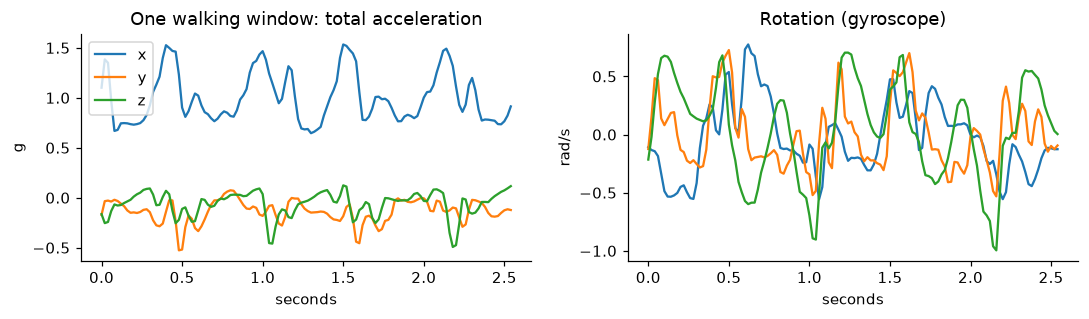

In [8]:
demo = pd.read_csv(DEMO)
X = to_windows(demo, cfg)
print(f"sample recording: {len(demo):,} rows at 50 Hz ({demo.timestamp.iloc[-1]:.0f} s) -> {X.shape[0]} windows of {X.shape[1]} x {X.shape[2]}")
t = np.arange(128) / 50
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for i, axis in enumerate("xyz"):
    ax[0].plot(t, X[3, :, 6 + i], label=axis)   # channels 6-8: total acceleration
    ax[1].plot(t, X[3, :, 3 + i], label=axis)   # channels 3-5: rotation
ax[0].set(title="One walking window: total acceleration", xlabel="seconds", ylabel="g")
ax[1].set(title="Rotation (gyroscope)", xlabel="seconds", ylabel="rad/s")
ax[0].legend(); plt.tight_layout(); plt.show()

In [9]:
show(normalize)
Xn = normalize(X, cfg["norm_stats"])
print(f"before: mean {X.mean():.3f}, std {X.std():.3f}   after: mean {Xn.mean():.3f}, std {Xn.std():.3f}")

def normalize(X, path):
    s = np.load(path)
    return (X - s["mean"]) / s["std"]

before: mean 0.096, std 0.385   after: mean -0.009, std 0.872


## 3. Checking a recording before predicting · Shravya
**What to say**
- `validate_csv` runs before the model ever sees a file. The app shows its report: the estimated sampling rate, issues and warnings.
- It estimates the sampling rate from the median gap between timestamps, counts missing values, warns on gaps over 0.1 s and rejects gaps over 1 s. It also rejects missing columns, recordings shorter than one window, and values out of range, which usually means wrong units.
- Below, the real sample passes and three broken copies of it are caught.

In [10]:
from validation import validate_csv
show(validate_csv)

def validate_csv(df, cfg) -> dict:
    """Checks columns, sampling rate, missing readings. Returns {ok, issues, est_hz, warnings}; short gaps are warnings only."""
    issues, warnings, est_hz = [], [], None
    missing = [c for c in COLS if c not in df.columns]
    if missing:
        return {"ok": False, "est_hz": None, "issues": [f"missing columns: {missing}"]}

    n_nan = int(df[COLS].isna().sum().sum())
    if n_nan:
        issues.append(f"{n_nan} NaN values")
    d = df.dropna(subset=COLS)
    t = d["timestamp"].to_numpy(float)
    if len(t) < 2 or not np.all(np.diff(t) > 0):
        return {"ok": False, "est_hz": None, "issues": issues + ["too few rows or timestamps not increasing"]}

    gaps = np.diff(t)
    est_hz = float(1 / np.median(gaps))
    want = cfg["sampling_rate_hz"]
    if est_hz < (1 - HZ_TOL) * want:  # faster is fine: to_windows resamples to 50 Hz
        issues.append(f"sampling rate {est_hz:.1f} Hz, need >= {want} Hz")
    if np.percentile(gaps, 95) > 2 * np.median(gaps):  # ponytail: crude jitter test
        issues.append("uneven sampling (high gap spread)")
    n_gaps = int((gaps > SHORT_GAP).sum())
    if n_gaps:
        warnings.append(f"{n_gaps} time gaps > {SHORT_GAP}s (largest {gaps.max():.2f}s)")
    if gaps.max() > LONG_GAP:
        issues.append(f"long gap > {LONG_GAP}s: reject file")

    need = cfg["window_samples"] / want
    if t[-1] - t[0] < need:
        issues.append(f"only {t[-1] - t[0]:.2f}s of data, need >= {need:.2f}s")

    acc, gyro = d[["acc_x", "acc_y", "acc_z"]].to_numpy(float), d[["gyro_x", "gyro_y", "gyro_z"]].to_numpy(float)
    if np.abs(acc).max() > MAX_ACC_G:
        issues.append(f"|acc| up to {np.abs(acc).max():.1f} > {MAX_ACC_G} g (units?)")
    if np.abs(gyro).max() > MAX_GYRO:
        issues.append(f"|gyro| up to {np.abs(gyro).max():.1f} > {MAX_GYRO} rad/s (deg/s?)")
    if abs(np.median(np.linalg.norm(acc, axis=1)) - 9.8) < 1.0:
        issues.append("median |acc| ~9.8: looks like m/s^2, divide by 9.80665")

    return {"ok": not issues, "est_hz": est_hz, "issues": issues, "warnings": warnings}

In [11]:
def check(name, df):
    r = validate_csv(df, cfg)
    rate = f"{r['est_hz']:.0f} Hz" if r.get("est_hz") else "n/a"
    print(f"{name:40s} passes: {str(r['ok']):5s}  rate: {rate}")
    for m in r["issues"]:
        print("     issue:  ", m)
    for m in r.get("warnings", []):
        print("     warning:", m)

check("sample recording", demo)
check("gyro_z column missing", demo.drop(columns="gyro_z"))
check("2 seconds of readings lost", demo[(demo.timestamp < 30) | (demo.timestamp > 32)])
check("acceleration in m/s² instead of g", demo.assign(acc_x=demo.acc_x * 9.81, acc_y=demo.acc_y * 9.81, acc_z=demo.acc_z * 9.81))

sample recording                         passes: True   rate: 50 Hz
gyro_z column missing                    passes: False  rate: n/a
     issue:   missing columns: ['gyro_z']
2 seconds of readings lost               passes: False  rate: 50 Hz
     issue:   long gap > 1.0s: reject file
acceleration in m/s² instead of g        passes: False  rate: 50 Hz
     issue:   |acc| up to 19.9 > 8.0 g (units?)
     issue:   median |acc| ~9.8: looks like m/s^2, divide by 9.80665


## 4. Models, training and evaluation · Yash
**What to say**
- Three models: a Random Forest on UCI's 561 ready-made features (92.9%), a 1D-CNN on raw windows (91.0%, the model in the app), and an LSTM for comparison (88.1%).
- `build_cnn`: two 1D convolution layers, dropout, a dense layer, and a softmax over the six activities.
- `fit` trains with early stopping on three held-out training people and keeps the best epoch, so the model stops before it overfits.
- Below, the saved CNN is scored once on the 9 test people it never saw.

In [12]:
from models import build_cnn
from train import fit
show(build_cnn)
show(fit)

def build_cnn(input_shape=(128, 9), n_classes=6):
    from tensorflow import keras
    from tensorflow.keras import layers
    m = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv1D(64, 5, activation="relu"),
        layers.Conv1D(64, 5, activation="relu"),
        layers.Dropout(0.5),
        layers.MaxPooling1D(2),
        layers.Flatten(),
        layers.Dense(100, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def fit(model, X_tr, y_tr, X_val, y_val, cfg):
    """Returns (model, history). history is None for sklearn models."""
    if not hasattr(model, "compile"):                     # sklearn: no epochs
        return model.fit(X_tr, y_tr), None
    from tensorflow import keras
    keras.utils.set_random_seed(cfg["seed"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    h = model.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=30,
                  batch_size=64, callbacks=[stop], verbose=2)
    return model, h.history

In [13]:
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
model = tf.keras.models.load_model("models/cnn_uci.keras")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 124, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 120, 64)        │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 120, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3840)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       384,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           606 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,224,584 (4.67 MB)

 Trainable params: 408,194 (1.56 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 816,390 (3.11 MB)

9 people never seen: accuracy 91.0%, macro F1 0.909
per person: 2:92% 4:81% 9:82% 10:69% 12:95% 13:100% 18:97% 20:97% 24:100%


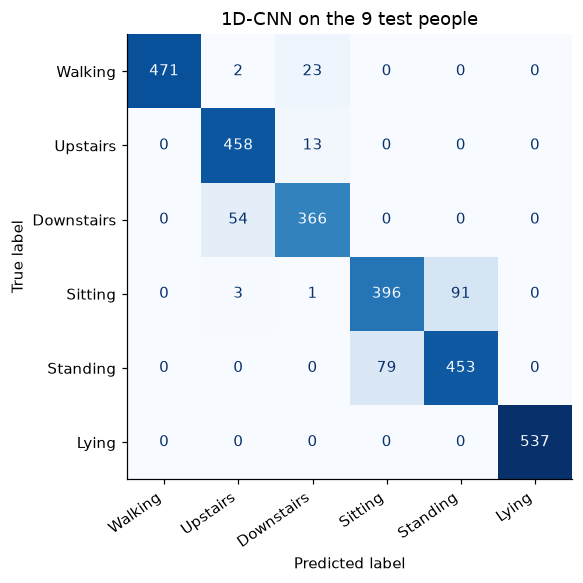

In [14]:
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from inference import ACTS
te = uci["test"]
pred = model.predict(normalize(te["X_raw"], cfg["norm_stats"]), verbose=0).argmax(1)
print(f"9 people never seen: accuracy {accuracy_score(te['y'], pred):.1%}, macro F1 {f1_score(te['y'], pred, average='macro'):.3f}")
per_person = pd.Series({s: accuracy_score(te["y"][te["subject"] == s], pred[te["subject"] == s]) for s in sorted(set(te["subject"]))})
print("per person:", " ".join(f"{s}:{a:.0%}" for s, a in per_person.items()))
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ConfusionMatrixDisplay.from_predictions(te["y"], pred, display_labels=[NAMES[a] for a in ACTS], ax=ax, colorbar=False, cmap="Blues")
ax.set_title("1D-CNN on the 9 test people"); plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

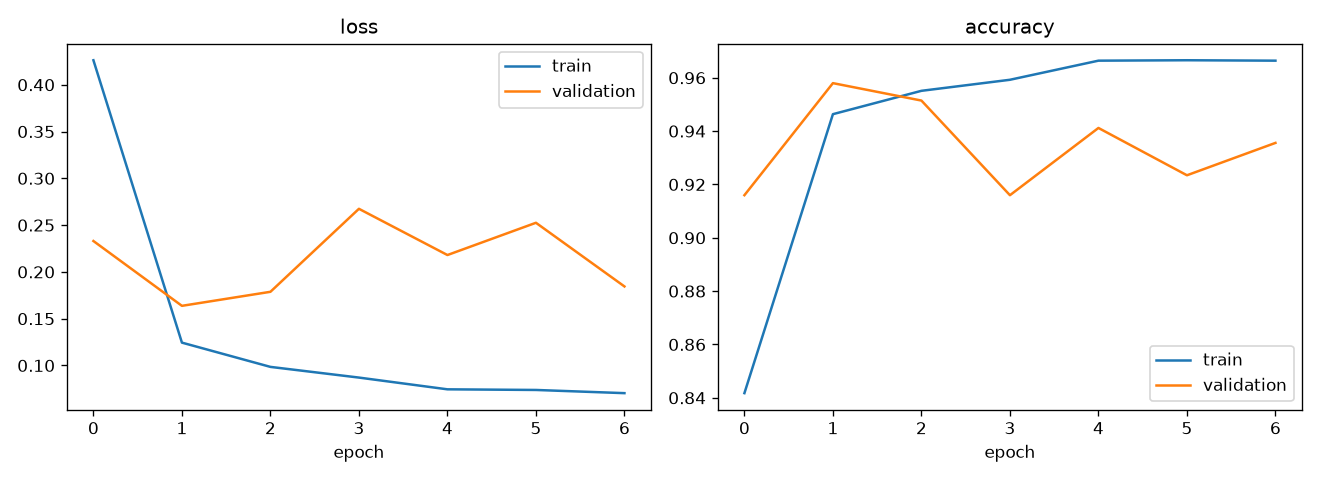

In [15]:
display(Image("reports/figures/learning_curves.png", width=760))

## 5. Prediction and the app · Yashaswini
**What to say**
- `predict_csv` is the path every recording takes: windows, normalise, the CNN, then one row per window with a start time, an activity and a confidence.
- `smooth` is a majority vote over five windows. It removes one-window flickers such as walk, sit, walk.
- The app calls exactly these functions. Below they run on the sample recording: two minutes of UCI test person 12, whom the model never trained on.

In [16]:
from inference import predict_csv, smooth
show(predict_csv)
show(smooth)

def predict_csv(path, model, cfg) -> pd.DataFrame:
    """One row per window: start_time, activity, confidence.

    `path` can be a file path or a file-like object (Streamlit upload).
    `model.predict(X)` must return class probabilities [N, 6].
    """
    df = pd.read_csv(path) if not isinstance(path, pd.DataFrame) else path
    X = normalize(to_windows(df, cfg), cfg["norm_stats"])
    if len(X) == 0:
        return pd.DataFrame(columns=["start_time", "activity", "confidence"])
    p = model.predict(X, verbose=0) if hasattr(model, "compile") else model.predict(X)
    step = cfg["window_samples"] * (1 - cfg["overlap"]) / cfg["sampling_rate_hz"]
    return pd.DataFrame({"start_time": df["timestamp"].min() + np.arange(len(X)) * step,
                         "activity": [ACTS[i] for i in p.argmax(1)],
                         "confidence": p.max(1).round(3)})

def smooth(pred_df, k=5) -> pd.DataFrame:
    """Centered rolling majority vote over `activity` (odd k, edges use a shorter window).

    Ties keep the original label if it is among the leaders. Returns a copy.
    """
    assert k % 2 == 1, "k must be odd"
    out, acts, h = pred_df.copy(), list(pred_df["activity"]), k // 2
    for i, orig in enumerate(acts):
        win = acts[max(0, i - h): i + h + 1]
        counts = {a: win.count(a) for a in set(win)}
        top = max(counts.values())
        if counts[orig] < top:
            out.iloc[i, out.columns.get_loc("activity")] = next(a for a in win if counts[a] == top)
    return out

95 windows, 99% right


,start_time,activity,confidence,truth
0,0.00,WALKING,0.605,WALKING
1,1.28,WALKING,0.956,WALKING
2,2.56,WALKING,0.951,WALKING
3,3.84,WALKING,0.875,WALKING
4,5.12,WALKING,0.913,WALKING
5,6.40,WALKING,0.877,WALKING


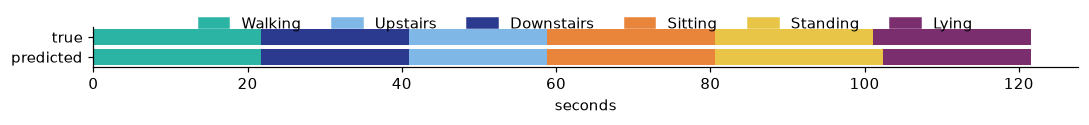

In [17]:
p = smooth(predict_csv(DEMO, model, cfg), cfg["smooth_window"])
# the sample was built from these stretches of person 12's recording (see README)
TRUTH = [("WALKING", 0, 23.04), ("WALKING_DOWNSTAIRS", 23.04, 41), ("WALKING_UPSTAIRS", 41, 59),
         ("SITTING", 59, 81), ("STANDING", 81, 102), ("LAYING", 102, 124.2)]
p["truth"] = [next((a for a, s, e in TRUTH if s <= t + 1.28 < e), None) for t in p.start_time]
print(f"{len(p)} windows, {(p.activity == p.truth).mean():.0%} right")
display(p.head(6))
fig, ax = plt.subplots(figsize=(10, 1.9))
for row, col in ((1, "truth"), (0, "activity")):
    for t, a in zip(p.start_time, p[col]):
        ax.barh(row, 1.28, left=t, color=COLOURS[a], height=0.8)
ax.set_yticks([0, 1], ["predicted", "true"]); ax.set_xlabel("seconds")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLOURS[a]) for a in ACTS]
ax.legend(handles, [NAMES[a] for a in ACTS], ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.6), frameon=False)
plt.tight_layout(); plt.show()

In [18]:
for i, line in enumerate(open("app/home.py", encoding="utf-8"), 1):
    if any(k in line for k in ("validate_csv(", "predict_csv(", "smooth(")):
        print(f"app/home.py line {i}: {line.strip()}")

app/home.py line 125: rep = validate_csv(df, cfg)
app/home.py line 136: pred = predict_csv(df, model, cfg)
app/home.py line 138: pred = smooth(pred, cfg["smooth_window"])


## 6. Activity from video · Yyug
**What to say**
- Our own recordings are phone videos, not sensor data, so a second pipeline reads the body. MediaPipe finds 33 body points in every frame (`extract_keypoints`).
- `body_point_features` reads those points on undistorted geometry, in a 3D body frame built from MediaPipe's depth estimate (so the camera angle matters less), and adds whole-body movement: 42 numbers per 2-second window.
- `_classify`: one Random Forest says walking, standing or stairs; a second says up or down for stairs windows.
- Tested fairly, leaving one person out each time: 64% of windows right (macro F1 0.65; guessing gives 0.33), stairs direction right 85% of the time.

In [19]:
from video_pose import body_point_features, _classify
show(body_point_features)
show(_classify)

def body_point_features(iso_window, raw_window, size, fps=25) -> np.ndarray:
    """42 features of one window: the 23 of pose_features on undistorted points, 15 from a 3D body
    frame (MediaPipe x, y and depth z, turned so the torso is the vertical axis: independent of the
    camera angle), 4 on whole-body movement through the frame (travel and approach speed)."""
    P = np.asarray(raw_window, float)[:, :, :3] * [size[0], size[1], size[0]]
    hip, sh = P[:, [23, 24]].mean(1), P[:, [11, 12]].mean(1)
    u = (sh - hip).mean(0); u /= np.linalg.norm(u)
    l = (P[:, 24] - P[:, 23]).mean(0); l -= (l @ u) * u; l /= np.linalg.norm(l)
    torso = np.linalg.norm(sh - hip, axis=1)
    B = np.stack([(P - hip[:, None]) @ a for a in (l, u, np.cross(u, l))], -1) / torso.mean()
    knee = (_angle(B[:, 23], B[:, 25], B[:, 27]) + _angle(B[:, 24], B[:, 26], B[:, 28])) / 2
    hipflex = (_angle(B[:, 11], B[:, 23], B[:, 25]) + _angle(B[:, 12], B[:, 24], B[:, 26])) / 2
    au, ku, af = B[:, [27, 28], 1], B[:, [25, 26], 1], B[:, [27, 28], 2]
    vel = np.diff(B, axis=0) * fps
    sp = lambda ids, ax: np.abs(vel[:, ids, ax]).mean()
    step = _periodic(af[:, 0] - af[:, 1], fps)
    body = [knee.mean(), knee.std(), knee.min(), np.ptp(knee), hipflex.mean(), np.ptp(hipflex),
            np.ptp(au, axis=0).mean(), np.abs(au[:, 0] - au[:, 1]).mean(), np.abs(au[:, 0] - au[:, 1]).max(),
            np.ptp(ku, axis=0).mean(), sp([27, 28], 1), sp([27, 28], 2), sp([25, 26], 1), step[0], step[2]]
    t2 = np.linalg.norm(sh[:, :2] - hip[:, :2], axis=1)  # torso length in the image plane
    d = np.diff(hip[:, :2], axis=0) * fps / t2[1:, None]
    ls = np.diff(np.log(t2)) * fps
    move = [np.linalg.norm(d, axis=1).mean(), np.abs(d[:, 1]).mean(), np.abs(ls).mean(), np.abs(ls.mean())]
    return np.concatenate([pose_features(iso_window, fps), body, move])

def _classify(F, bundle):
    """Features [N, 23] -> (activity names, confidence). If the bundle has a "direction" model
    (notebooks/09_stairs_direction.py), windows called stairs become upstairs / downstairs and their
    confidence becomes P(stairs) * P(direction)."""
    p = bundle["model"].predict_proba(F)
    act = np.array([bundle["classes"][i] for i in p.argmax(1)], dtype=object)
    conf = p.max(1)
    d, m = bundle.get("direction"), act == "stairs"
    if d and m.any():
        q = d["model"].predict_proba(F[m])
        act[m] = [d["classes"][i] for i in q.argmax(1)]
        conf[m] = conf[m] * q.max(1)
    return act, conf

The 33 body points MediaPipe found in clip A (8), where a person walks up toward the camera and then back down. Only the points are drawn, never the video, so no one's face is stored.

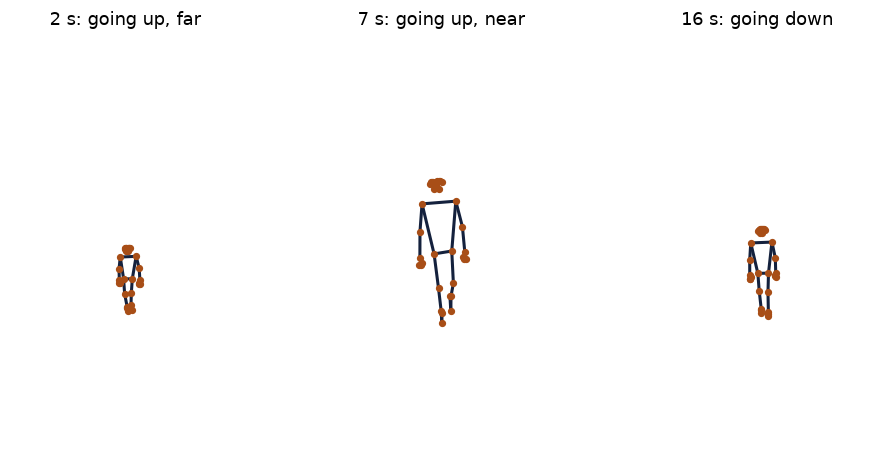

In [20]:
kp_file = "data/video/keypoints/p1_stairs_05.npz"
EDGES = [(11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (11, 23), (12, 24), (23, 24), (23, 25), (25, 27),
         (24, 26), (26, 28), (27, 29), (28, 30), (29, 31), (30, 32), (27, 31), (28, 32)]
if os.path.exists(kp_file):
    kp = np.load(kp_file)["kp"]
    fig, axes = plt.subplots(1, 3, figsize=(9, 4.2))
    for ax, sec, label in zip(axes, (2, 7, 16), ("going up, far", "going up, near", "going down")):
        P = kp[int(sec * 25), :, :2] * [576, 1024]
        for a, b in EDGES:
            ax.plot(P[[a, b], 0], P[[a, b], 1], color="#14213D", lw=2)
        ax.scatter(P[:, 0], P[:, 1], s=14, color="#A84E17", zorder=3)
        ax.set_title(f"{sec} s: {label}"); ax.set_xlim(0, 576); ax.set_ylim(1024, 0); ax.set_aspect("equal"); ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Our keypoints are not on GitHub (privacy). The saved figure above was made on the laptop.")

In [21]:
import joblib
from video_pose import MODEL, predict_video
clip = "../videos/A (8).mp4"
if os.path.exists(clip) and os.path.exists(MODEL):
    v = predict_video(clip, joblib.load(MODEL), cfg)
    print("clip A (8), one label per 2-second window, every second:")
    print(" ".join(f"{t:.0f}s:{a}" for t, a in zip(v.start_time, v.activity)))
    print("This clip was used in training, so this shows how the pipeline works, not how accurate it is.")
else:
    print("Our videos are not on GitHub (privacy). The saved output above was made on the laptop.")

clip A (8), one label per 2-second window, every second:
0s:upstairs 1s:upstairs 2s:upstairs 3s:upstairs 4s:upstairs 5s:upstairs 6s:upstairs 7s:upstairs 8s:upstairs 9s:downstairs 10s:downstairs 11s:downstairs 12s:downstairs 13s:downstairs 14s:downstairs 15s:downstairs 16s:downstairs 17s:downstairs 18s:downstairs
This clip was used in training, so this shows how the pipeline works, not how accurate it is.


In [22]:
pd.DataFrame([
    ("Phone model (1D-CNN)", "9 UCI people never seen", "91.0%", "0.909", "random guessing: 17%"),
    ("Camera model", "each of our 4 people, left out in turn", "64%", "0.65", "random guessing: 0.33 macro F1"),
    ("Stairs direction (up or down)", "each of our 4 people, left out in turn", "85% (side views 80%)", "", "shuffled labels: 50%"),
], columns=["Model", "Tested on", "Accuracy", "Macro F1", "Baseline"])

,Model,Tested on,Accuracy,Macro F1,Baseline
0,Phone model (1D-CNN),9 UCI people never seen,91.0%,0.909,random guessing: 17%
1,Camera model,"each of our 4 people, left out in turn",64%,0.65,random guessing: 0.33 macro F1
2,Stairs direction (up or down),"each of our 4 people, left out in turn",85% (side views 80%),,shuffled labels: 50%
